# Oversampling

### <i> Using SMOTE


<i> Creates synthetic samples specifically for the minority class, based on nearest neighbors. (Yes, KNN!) It's quite a useful way to synthesize data when you want to ensure the rarer combinations need representation.

In [64]:
# pip install imblearn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# load dataset
df = pd.read_csv("../..//houses.csv")

# drop unneeded variables
df.drop(["id", "date", "lat", "long", 'zipcode'], axis=1, inplace=True)

df

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
0,221900.00,3,1.00,1180,5650,1.00,0,0,3,7,1180,0,1955,0,1340,5650
1,538000.00,3,2.25,2570,7242,2.00,0,0,3,7,2170,400,1951,1991,1690,7639
2,180000.00,2,1.00,770,10000,1.00,0,0,3,6,770,0,1933,0,2720,8062
3,604000.00,4,3.00,1960,5000,1.00,0,0,5,7,1050,910,1965,0,1360,5000
4,510000.00,3,2.00,1680,8080,1.00,0,0,3,8,1680,0,1987,0,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.00,3,2.50,1530,1131,3.00,0,0,3,8,1530,0,2009,0,1530,1509
21609,400000.00,4,2.50,2310,5813,2.00,0,0,3,8,2310,0,2014,0,1830,7200
21610,402101.00,2,0.75,1020,1350,2.00,0,0,3,7,1020,0,2009,0,1020,2007
21611,400000.00,3,2.50,1600,2388,2.00,0,0,3,8,1600,0,2004,0,1410,1287


In [65]:
# remove NaNs
df = df.dropna()

---

### The problem

<Axes: xlabel='waterfront', ylabel='Count'>

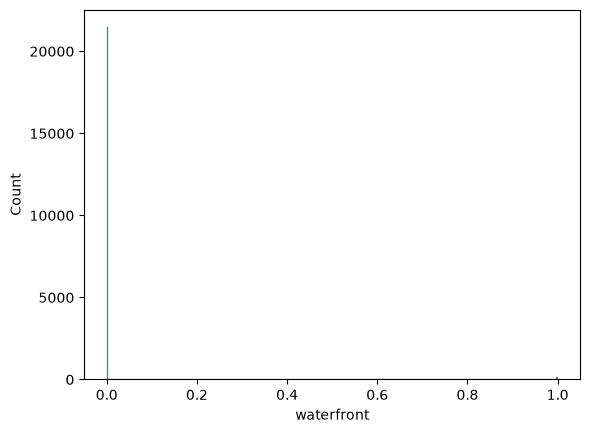

In [66]:
# Say that we're trying to make a machine learning model that
# predicts whether or not a home has a pool...

# And we look at this distribution and find that there's something very wrong.
sns.histplot(df, x="waterfront")

# The number of pools we have is massively underrepresented!
# And assume that we cannot collect any more data than this. 

# We have to create some data in order to represent the values better.

In [67]:
df['waterfront'].value_counts()

waterfront
0    21450
1      163
Name: count, dtype: int64

---

### SMOTE

In [68]:
df.shape

(21613, 16)

In [69]:
# Another x y split to prevent a data leakage
X = df.drop(columns="waterfront", axis=1)
y = df['waterfront']


<Axes: xlabel='waterfront', ylabel='Count'>

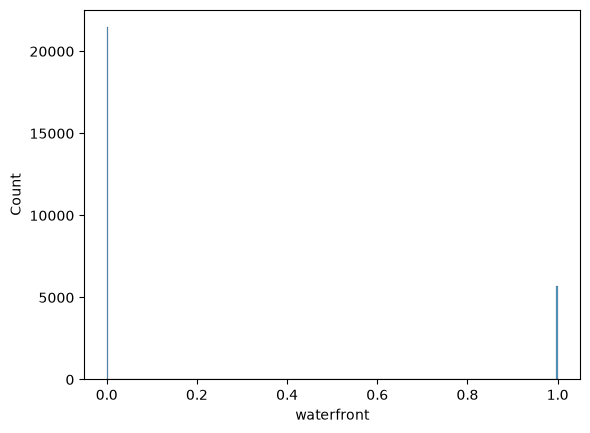

In [70]:
from imblearn.over_sampling import SMOTE

strategy = {
    0: 21450,
    1: 5713
}

smote = SMOTE(sampling_strategy=strategy)

X_resampled, y_resampled = smote.fit_resample(X, y)

# reconstruct the dataframe
df_oversampled_smote = pd.DataFrame(X_resampled)
df_oversampled_smote["waterfront"] = y_resampled

sns.histplot(df_oversampled_smote, x="waterfront")

In [71]:
df_oversampled_smote.shape

(27163, 16)

In [72]:
df_oversampled_smote['waterfront'].value_counts()

waterfront
0    21450
1     5713
Name: count, dtype: int64

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>WARNING</h3>

Notice how many more rows we created here? <strong style='color:orange ; background-color:black;'> We have to be VERY careful to ensure that our data still reflects reality. </strong>

In this case, we added WAY too many rows. Not everyone has a pool! And what's worse, synthetic data is really volatile. 

</div>

In [73]:
# switching to decimal notation for the variance checks
pd.set_option('display.float_format', lambda x: "%.2f" % x)

In [74]:
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
count,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00
mean,540088.14,3.37,2.11,2079.90,15106.97,1.49,0.01,0.23,3.41,7.66,1788.39,291.51,1971.01,84.40,1986.55,12768.46
std,367127.20,0.93,0.77,918.44,41420.51,0.54,0.09,0.77,0.65,1.18,828.09,442.58,29.37,401.68,685.39,27304.18
min,75000.00,0.00,0.00,290.00,520.00,1.00,0.00,0.00,1.00,1.00,290.00,0.00,1900.00,0.00,399.00,651.00
25%,321950.00,3.00,1.75,1427.00,5040.00,1.00,0.00,0.00,3.00,7.00,1190.00,0.00,1951.00,0.00,1490.00,5100.00
50%,450000.00,3.00,2.25,1910.00,7618.00,1.50,0.00,0.00,3.00,7.00,1560.00,0.00,1975.00,0.00,1840.00,7620.00
75%,645000.00,4.00,2.50,2550.00,10688.00,2.00,0.00,0.00,4.00,8.00,2210.00,560.00,1997.00,0.00,2360.00,10083.00
max,7700000.00,33.00,8.00,13540.00,1651359.00,3.50,1.00,4.00,5.00,13.00,9410.00,4820.00,2015.00,2015.00,6210.00,871200.00


In [75]:
df_oversampled_smote.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15,waterfront
count,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00
mean,762584.04,3.28,2.22,2290.02,16555.52,1.52,0.93,3.38,7.80,1912.73,377.20,1969.11,167.41,2124.22,14385.49,0.21
std,726857.25,0.94,0.85,1129.97,38589.14,0.53,1.56,0.63,1.31,923.36,521.73,28.56,505.55,750.10,25594.11,0.41
min,75000.00,0.00,0.00,290.00,520.00,1.00,0.00,1.00,1.00,290.00,0.00,1900.00,0.00,399.00,651.00,0.00
25%,350000.00,3.00,1.75,1500.00,5737.00,1.00,0.00,3.00,7.00,1240.00,0.00,1950.00,0.00,1546.50,5739.00,0.00
50%,520500.00,3.00,2.25,2058.00,8560.00,1.50,0.00,3.00,8.00,1670.00,0.00,1970.00,0.00,1971.00,8437.00,0.00
75%,815000.00,4.00,2.50,2800.00,14692.00,2.00,2.00,4.00,8.00,2390.00,700.00,1993.00,0.00,2594.50,13340.00,0.00
max,7700000.00,33.00,8.00,13540.00,1651359.00,3.50,4.00,5.00,13.00,9410.00,4820.00,2015.00,2015.00,6210.00,871200.00,1.00


In [76]:
df.var(numeric_only=True)

price           134782378397.25
bedrooms                   0.87
bathrooms                  0.59
sqft_living           843533.68
sqft_lot          1715658774.18
floors                     0.29
waterfront                 0.01
view                       0.59
condition                  0.42
grade                      1.38
sqft_above            685734.67
sqft_basement         195872.67
yr_built                 862.80
yr_renovated          161346.21
sqft_living15         469761.24
sqft_lot15         745518225.34
dtype: float64

In [77]:
df_oversampled_smote.var(numeric_only=True)

price           528321465364.94
bedrooms                   0.89
bathrooms                  0.73
sqft_living          1276835.52
sqft_lot          1489121681.33
floors                     0.28
view                       2.44
condition                  0.40
grade                      1.73
sqft_above            852585.45
sqft_basement         272207.01
yr_built                 815.86
yr_renovated          255582.32
sqft_living15         562654.61
sqft_lot15         655058705.24
waterfront                 0.17
dtype: float64

<Axes: >

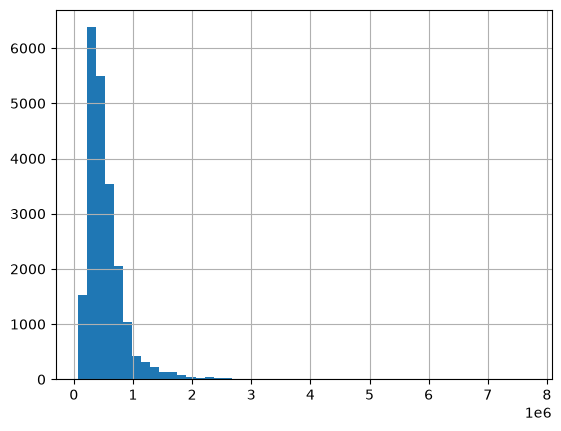

In [78]:
df['price'].hist(bins=50)

<Axes: >

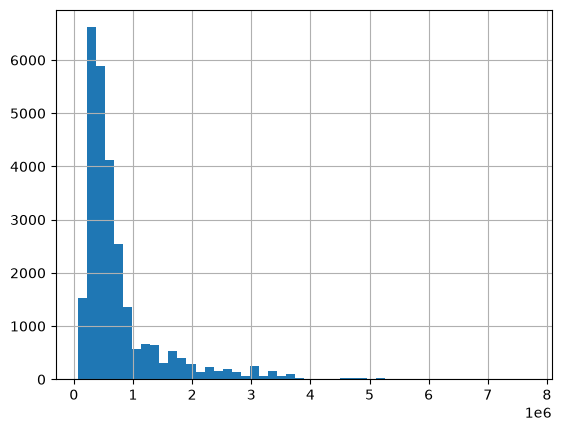

In [79]:
df_oversampled_smote['price'].hist(bins=50)

In [ ]:
# to be added later => extract only the synthetic ones from the oversampled df
# so we can actually study the synthesized houses here